#Decaimiento radioactivo por metodo de monte Carlo
Utilizaremos un simple juego de dados para simular el decaimiento radioactivo de una material radioactivo generico. Unicamente hay que demostrar que decae de la manera
$$
N(t) = N_0 e^{-kt}
$$
Utilizaremos un dado de N caras, una cantidad D de dados y previamente eligiremos un numero $1\leq a \leq N$. Representaremos los atomos como los dados y los lanzaremos todos al aire de tal manera cuando alguno caiga en el valor "$a$" estos se eliminan. Una vez terminamos estre proceso lo repetiremos denuevo.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import time

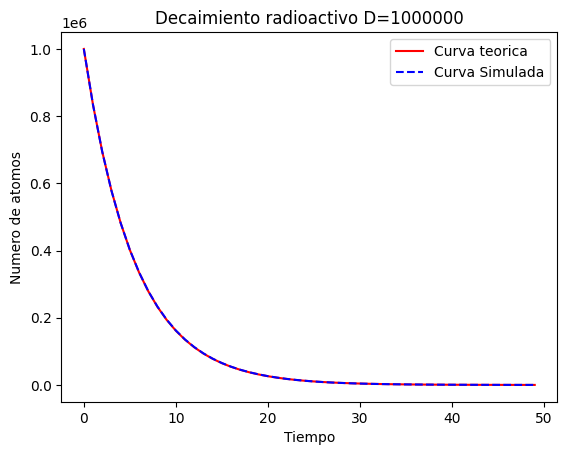

In [2]:
#Parametros iniciales
#Numero de dados
D = 1000000
#Cantidad de caras por dado
N = 6
#Valor de eliminacion 1<a<N
a = np.random.randint(1, N + 1)
#Generaciones
t = np.arange(0,50)
#Cantidad de dados o particulas que quedan despues de decaimiento
DCum =np.zeros(t.size)

for i in range(t.size):
  DCum[i] = D
  Condicion = np.random.randint(1, N + 1, size=D) #Se genera un arreglo de tamaño D(la cantidad de particulas que aun tenemos) de numeros aleatorios entre [1,N]
  AtomosDecaidos = np.sum(Condicion == a) #Condicion == a, devuelve un arreglo booleano indicando cuales particulas son las que decaen y se suma para conseguir la cantidad de atomos que decaen
  D -= AtomosDecaidos #Finalmente se resta de la cantidad total de atomos que hay

#Realizaremos la grafica teorica de decaimiento para un dado de 6 caras
k = np.log(N/(N-1))
FuncTeorica = DCum[0]*np.exp(-t*k)
plt.plot(t,FuncTeorica,'-', color = "r", label = "Curva teorica")
plt.plot(t,DCum,"--", color = "b", label = "Curva Simulada")
plt.xlabel("Tiempo")
plt.ylabel("Numero de atomos")
plt.title("Decaimiento radioactivo D=1000000")
plt.legend()
plt.show()

#Fision nuclear por metodos de MonteCarlo

In [3]:
#Condiciones inciales para neutrones termicos
sigma_fU235 = 584
sigma_fU238 = 0
sigma_aU235 = 97
sigma_aU238 = 2.75

#Probabilidad de fision cuando incide un neutron termico sobre el isotopo
Prob_Fision_U235 = sigma_fU235/(sigma_fU235 + sigma_aU235)
Prob_Fision_U238 = sigma_fU238/(sigma_fU238 + sigma_aU238)

In [4]:
def Concentraciones(C_U235):
  #Concentraciones iniciales de isotopos en el material
  Total = 1
  C_U235 = C_U235
  C_U238 = Total - C_U235

  #Seccion transversal total del U235
  sigma_total_U235 = sigma_fU235 + sigma_aU235

  #Probabilidad de golpe al Uranio 235 en una masa con distribucion homogenea de Uranio
  Prob_hit_U235 = C_U235 * sigma_total_U235 / (C_U235 * sigma_total_U235 + C_U238 * sigma_aU238)
  return C_U235, C_U238, Prob_hit_U235

C_U235, C_U238, Prob_hit_U235 = Concentraciones(0.0072)
print("Probabilidad de hit U235:",Prob_hit_U235)
k = 2.5 *  C_U235 * sigma_fU235 / (C_U235 * sigma_fU235 + C_U235*sigma_aU235 + C_U238*sigma_aU238)
print("Valor de k:",k)

Probabilidad de hit U235: 0.6423350014410355
Valor de k: 1.3771058768045692


In [5]:
def Simulacion(N, G, Prob_hit_U235):
  Generaciones = np.zeros(G, dtype = int)
  Generaciones[0] = N
  k = np.zeros(G - 1)
  for i in range(G-1):
    for j in range(Generaciones[i]):
      if random.random() < Prob_hit_U235:
        if random.random() < Prob_Fision_U235:
          Generaciones[i+1] += random.randint(2,3)

    k[i] = Generaciones[i+1]/(Generaciones[i])

    '''
    print("Reproduccion de neutrones generacion",i,":", k[i])
    print("Numero de Neutrones generados en generacion",i,":", Generaciones[i])
    print("Energia total :",Energia_Total, "Joules")
  print("Numero total de particulas simuladas:",np.max(np.cumsum(Generaciones)))
    '''
  return Generaciones, k

In [6]:
def SimulacionOpt(N, G, Prob_hit_U235):
    #inicializamos la cantidad de generaciones que se van a simular
    Generaciones = np.zeros(G, dtype=int)
    #La cantidad inicial de Neutrones
    Generaciones[0] = N
    #Numero de factores de generacion de neutrones a generar
    k = np.zeros(G - 1)

    for i in range(G - 1):
        n = Generaciones[i]
        #Si el numero de neutrones decae a 0 se para la simulacion
        if n == 0:
            break
        '''
        Las siguientes tres funciones estan comentadas y solo el valor n_fisiones se mantiene
        porque es ligeramente mas rapido.

        #Calcula cuales neutrones golpean su objetivo
        hits = np.random.random(n) < Prob_hit_U235

        #Calcula cuantos neutrones golpean el objetivo
        n_hits = np.sum(hits)

        #Calcula cuales de estos realizan fision
        fisiones = np.random.random(n_hits) < Prob_Fision_U235
        '''
        #Estos tres pasos anteriores se acortaron a una sola funcion, para su compresion es necesario lo anterior
        #Calcula cuantos neutrones realizan la fision
        n_fissions = np.sum(np.random.random(np.sum(np.random.random(n) < Prob_hit_U235)) < Prob_Fision_U235)

        #Si el numero de fisiones es mayor que 0
        if n_fissions > 0:
            #Se generan n_fissions numeros aleatorios entre 2 y 4
            nuevos_neutrones = np.sum(np.random.randint(2, 4, size = n_fissions))
            #Se colocan en la siguiente generacion
            Generaciones[i + 1] += nuevos_neutrones
        #Calculamos el factor de reproduccion por definicion
        k[i] = Generaciones[i + 1] / n
        '''
        print("Numero de neutrones en generacion ", i, ":", Generaciones[i])
        print("Valor de reproduccion de neutrones k:", k[i])
    print("Numero total de particulas simuladas:", np.max(np.cumsum(Generaciones)))
    print("Energia total liberada:" ,Energia_Total, "Joules")
    '''
    return Generaciones, k

K promedio: 1.0018872288422886
K teorica 1.0
Porcentaje de error: 0.18872288422886463


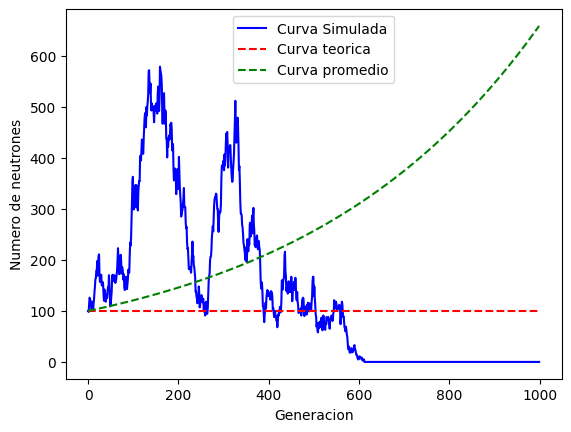

In [7]:
C_U235, C_U238, Prob_hit_U235 = Concentraciones(11/3127)
Generaciones, k = SimulacionOpt(100, 1000, Prob_hit_U235)

t = np.arange(Generaciones.size)

k = k[k != 0]
kt = 2.5 *  C_U235 * sigma_fU235 / (C_U235 * sigma_fU235 + C_U235*sigma_aU235 + C_U238*sigma_aU238)
kmean = np.mean(k)

N = Generaciones[0]* np.exp((kt-1)*t)
NPromedio = Generaciones[0]* np.exp((kmean-1)*t)

PorcentajeError = np.abs(kmean-kt)/kt*100

print("K promedio:", kmean)
print("K teorica", kt)
print("Porcentaje de error:", PorcentajeError)

plt.plot(t,Generaciones,"-", color = "b", label = "Curva Simulada")
plt.plot(t,N,'--', color = "r", label = "Curva teorica")
plt.plot(t,NPromedio,'--', color = "g", label = "Curva promedio")
plt.xlabel("Generacion")
plt.ylabel("Numero de neutrones")

plt.legend()
plt.show()

K promedio: 1.1060102157517053
K teorica 1.1079198267000205
Porcentaje de error: 0.17236003023820376


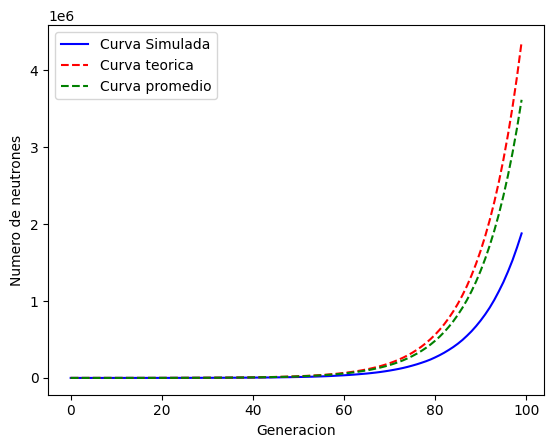

In [8]:
C_U235, C_U238, Prob_hit_U235 = Concentraciones(0.0043)
Generaciones, k = SimulacionOpt(100, 100, Prob_hit_U235)

t = np.arange(Generaciones.size)

kt = 2.5 *  C_U235 * sigma_fU235 / (C_U235 * sigma_fU235 + C_U235*sigma_aU235 + C_U238*sigma_aU238)
kmean = np.mean(k)

N = Generaciones[0]* np.exp((kt-1)*t)
NPromedio = Generaciones[0]* np.exp((kmean-1)*t)

PorcentajeError = np.abs(kmean-kt)/kt*100

print("K promedio:", kmean)
print("K teorica", kt)
print("Porcentaje de error:", PorcentajeError)

plt.plot(t,Generaciones,"-", color = "b", label = "Curva Simulada")
plt.plot(t,N,'--', color = "r", label = "Curva teorica")
plt.plot(t,NPromedio,'--', color = "g", label = "Curva promedio")
plt.xlabel("Generacion")
plt.ylabel("Numero de neutrones")

plt.legend()
plt.show()

K promedio: 0.7360829984211608
K teorica 0.7110678193108487
Porcentaje de error: 3.5179737334416568


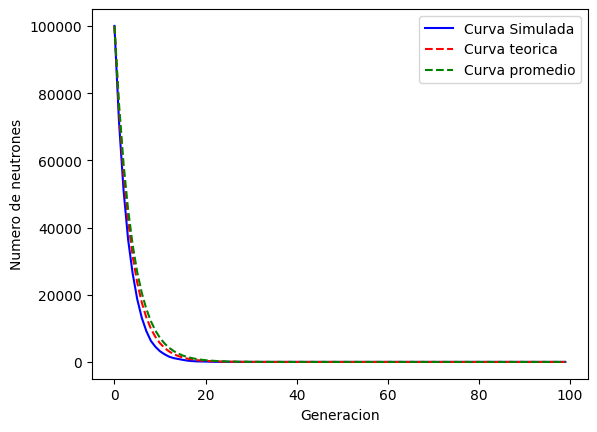

In [9]:
C_U235, C_U238, Prob_hit_U235 = Concentraciones(0.002)
Generaciones, k = SimulacionOpt(100000, 100, Prob_hit_U235)

t = np.arange(Generaciones.size)

k = k[k != 0]
kt = 2.5 *  C_U235 * sigma_fU235 / (C_U235 * sigma_fU235 + C_U235*sigma_aU235 + C_U238*sigma_aU238)
kmean = np.mean(k)

N = Generaciones[0]* np.exp((kt-1)*t)
NPromedio = Generaciones[0]* np.exp((kmean-1)*t)

PorcentajeError = np.abs(kmean-kt)/kt*100

print("K promedio:", kmean)
print("K teorica", kt)
print("Porcentaje de error:", PorcentajeError)

plt.plot(t,Generaciones,"-", color = "b", label = "Curva Simulada")
plt.plot(t,N,'--', color = "r", label = "Curva teorica")
plt.plot(t,NPromedio,'--', color = "g", label = "Curva promedio")
plt.xlabel("Generacion")
plt.ylabel("Numero de neutrones")

plt.legend()
plt.show()

In [10]:
C_U235, C_U238, Prob_hit_U235 = Concentraciones(0.0073)
Gen = 30
Rep = 5000
k1=np.zeros((Rep,Gen-1))
for i in range(Rep):
  Generaciones1, k1[i] = SimulacionOpt(100, Gen, Prob_hit_U235)


K promedio: 1.3838939621102682
K teorica: 1.3839356725715712
Porcentaje de error: 0.003013901739058059


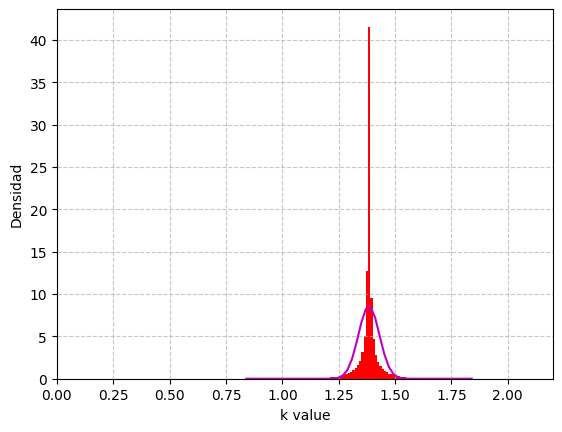

In [11]:
C_U235, C_U238, Prob_hit_U235 = Concentraciones(0.0073)
kt = 2.5 *  C_U235 * sigma_fU235 / (C_U235 * sigma_fU235 + C_U235*sigma_aU235 + C_U238*sigma_aU238)
k1flat = k1.flatten()
KProm = np.mean(k1flat)
Kdev = np.std(k1flat)


print("K promedio:", KProm)
print("K teorica:", kt)
print("Porcentaje de error:", np.abs(KProm-kt)/kt*100)


X1 = np.linspace(k1flat.min(), k1flat.max())
Y1 = 1/(Kdev*np.sqrt(2*np.pi))*np.exp(-(X1-KProm)**2/(2*Kdev**2))

plt.hist(k1flat, bins=100, density=True, color='r')
plt.plot(X1,Y1, color = "m")
plt.xlabel('k value')
plt.ylabel('Densidad')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(0,2.2)
plt.show()

In [12]:
C_U235, C_U238, Prob_hit_U235 = Concentraciones(0.0035177678)
Gen = 50
Rep = 30000
k2=np.zeros((Rep,Gen-1))
for i in range(Rep):
  Generaciones, k2[i] = SimulacionOpt(100, Gen, Prob_hit_U235)

K promedio: 1.0019121577586996
K teorica: 1.0000029162511241
Porcentaje de error: 0.19092359397639766


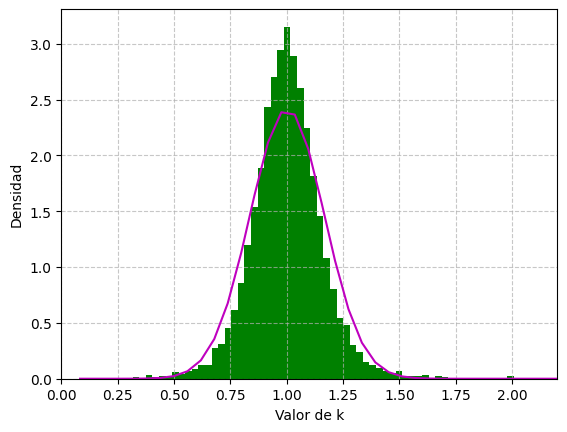

In [13]:
C_U235, C_U238, Prob_hit_U235 = Concentraciones(0.0035177678)
kt = 2.5 *  C_U235 * sigma_fU235 / (C_U235 * sigma_fU235 + C_U235*sigma_aU235 + C_U238*sigma_aU238)
k2flat = k2.flatten()
k2flat = k2flat[k2flat != 0]
KProm = np.mean(k2flat)
Kdev = np.std(k2flat)


print("K promedio:", KProm)
print("K teorica:", kt)
print("Porcentaje de error:", np.abs(KProm-kt)/kt*100)

X2 = np.linspace(k2flat.min(), k2flat.max())
Y2 = 1/(Kdev*np.sqrt(2*np.pi))*np.exp(-(X2-KProm)**2/(2*Kdev**2))

plt.hist(k2flat, bins=100, density=True, color='g')
plt.plot(X2,Y2, color = "m")
plt.xlabel('Valor de k')
plt.ylabel('Densidad')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(0,2.2)
plt.show()

In [14]:
C_U235, C_U238, Prob_hit_U235 = Concentraciones(0.002)
Gen = 50
Rep = 200000
k3=np.zeros((Rep,Gen-1))
for i in range(Rep):
  Generaciones, k3[i] = SimulacionOpt(100, Gen, Prob_hit_U235)

K promedio: 0.779923767497092
K teorica: 0.7110678193108487
Porcentaje de error: 9.683457233794798


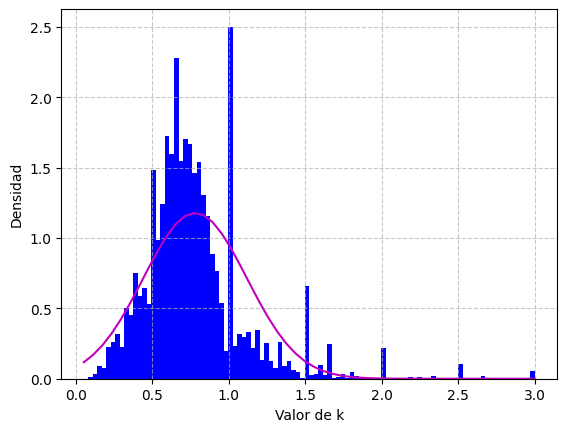

In [15]:
C_U235, C_U238, Prob_hit_U235 = Concentraciones(0.002)
kt = 2.5 *  C_U235 * sigma_fU235 / (C_U235 * sigma_fU235 + C_U235*sigma_aU235 + C_U238*sigma_aU238)
k3flat = k3.flatten()
k3flat = k3flat[k3flat != 0]
KProm = np.mean(k3flat)
Kdev = np.std(k3flat)

print("K promedio:", KProm)
print("K teorica:", kt)
print("Porcentaje de error:", np.abs(KProm-kt)/kt*100)

X3 = np.linspace(k3flat.min(), k3flat.max())
Y3 = 1/(Kdev*np.sqrt(2*np.pi))*np.exp(-(X3-KProm)**2/(2*Kdev**2))

plt.hist(k3flat, bins=100, density=True, color='b')
plt.plot(X3,Y3, color = "m")
plt.xlabel('Valor de k')
plt.ylabel('Densidad')
plt.title('')
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

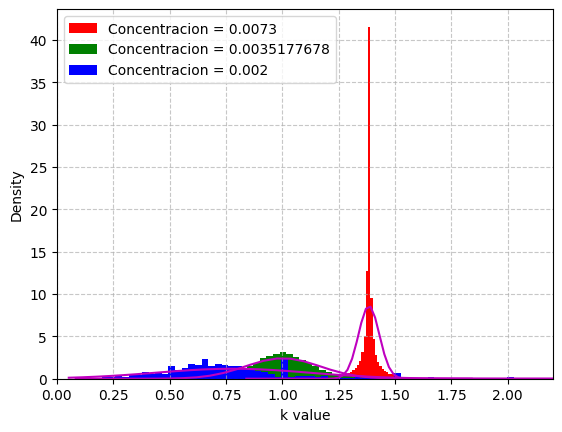

In [16]:
plt.hist(k1flat, bins=100, density=True, color='r', label = "Concentracion = 0.0073")
plt.plot(X1,Y1, color = "m")
plt.hist(k2flat, bins=100, density=True, color='g', label = "Concentracion = 0.0035177678")
plt.plot(X2,Y2, color = "m")
plt.hist(k3flat, bins=100, density=True, color='b', label = "Concentracion = 0.002")
plt.plot(X3,Y3, color = "m")
plt.xlabel('k value')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.xlim(0,2.2)
plt.show()